# Coverage QC

Per-gene-window coverage from `results/<sample>/body/block_*.tsv.gz`, and whether coverage affects the
cell-type correlations.

Edit `SAMPLES` below. Requires numpy, pandas, matplotlib; scipy optional.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SAMPLES = ["IA01"]                 # e.g. ["IH02", "healthy", "cancer"]
WORKFLOW = Path("..")
BAND = (193, 199)                  # bp, the band collapse_fft_wps.py scores
PERIOD_RANGE = (120, 280)          # bp, the range fft_path.R writes
DROP_QUANTILES = [0.0, 0.01, 0.05, 0.10, 0.25, 0.50]   # share of worst-covered windows to test dropping
N_EXAMPLES = 3
OUT_DIR = Path("qc_output"); OUT_DIR.mkdir(exist_ok=True)

REF_CSV = WORKFLOW / "resources/avg_expr_by_celltype_tissue.csv"
COMPARTMENT_CSV = WORKFLOW / "resources/celltype_compartment.csv"
CONTROL_TYPES = {"erythrocyte", "platelet", "eye photoreceptor cell", "retinal bipolar neuron",
                 "retina horizontal cell", "retinal ganglion cell", "retinal pigment epithelial cell",
                 "cardiac muscle cell", "slow muscle cell", "fast muscle cell", "cell of skeletal muscle"}
LABELS = ["immune", "other", "negative control"]
LCOL = {"immune": "tab:red", "other": "#c3c2b7", "negative control": "#333333"}
SCOL = dict(zip(SAMPLES, ["#2a78d6", "#eb6834", "#1baf7a", "#d62728", "#7a5cc6"]))
MUTED, GRID, INK = "#898781", "#e1e0d9", "#333333"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.facecolor": "white", "figure.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "legend.frameon": False,
})

ref = pd.read_csv(REF_CSV, index_col=0).drop(columns=["gene_name"], errors="ignore")
comp = pd.read_csv(COMPARTMENT_CSV, index_col=0)["compartment"].reindex(ref.columns)
lab = pd.Series({g: ("negative control" if g.split("_", 1)[0] in CONTROL_TYPES
                     else "immune" if comp[g] == "immune" else "other") for g in ref.columns})
print(f"reference: {ref.shape[1]} groups x {ref.shape[0]:,} genes | "
      + ", ".join(f"{k}={int((lab == k).sum())}" for k in LABELS))
for s in SAMPLES:
    print(f"{s}: {len(list((WORKFLOW / 'results' / s / 'body').glob('block_*.tsv.gz'))):,} block files")

reference: 447 groups x 58,604 genes | immune=241, other=186, negative control=20
IA01: 13,689 block files


## 1. Per-window metrics

Read from each `block_<gene>.tsv.gz`: column 3 = coverage, column 4 = read starts, column 5 = WPS, one row per
base of the 10,001 bp window (row 0 = TSS, oriented 5'→3').

| column | definition |
|---|---|
| `zero_frac` | fraction of the window's bases with coverage 0 |
| `mean_cov` | mean coverage over the window |
| `longest_gap` | longest run of consecutive zero-coverage bases, bp |
| `starts` | total read starts in the window |
| `band_power` | mean FFT power over 193–199 bp = the gene score `collapse_fft_wps.py` writes |
| `band_ratio` | `band_power` / mean power over 120–280 bp; 1 = flat spectrum, >1 = peak at the band |

In [2]:
def window_qc(sample):
    body = WORKFLOW / "results" / sample / "body"
    rows = []
    for p in sorted(body.glob("block_*.tsv.gz")):
        a = pd.read_csv(p, sep="\t", header=None, usecols=[2, 3, 4], dtype=np.float32).to_numpy()
        cov, starts = a[:, 0], a[:, 1]
        z = (cov == 0).view(np.int8)
        if z.any():
            e = np.flatnonzero(np.diff(np.concatenate([[0], z, [0]])))
            gap = int((e[1::2] - e[::2]).max())
        else:
            gap = 0
        rows.append({"gene_id": p.name[6:-7], "zero_frac": (cov == 0).mean(), "mean_cov": cov.mean(),
                     "longest_gap": gap, "starts": starts.sum()})
    return pd.DataFrame(rows).set_index("gene_id")

def fft_matrix(sample):
    d = WORKFLOW / "results" / sample / "proj" / "fft_summaries"
    for name in (f"fft_{sample}_WPS.tsv.gz", f"fft_{sample}_WPS.tsv"):
        if (d / name).exists():
            m = pd.read_csv(d / name, sep="\t", index_col=0)
            m.columns = m.columns.astype(float)
            return m[sorted(m.columns)]
    raise SystemExit(f"no FFT matrix in {d}")

qc, fft = {}, {}
for s in SAMPLES:
    q, f = window_qc(s), fft_matrix(s)
    shared = q.index.intersection(f.index)
    q, f = q.loc[shared], f.loc[shared]
    per = f.columns.to_numpy()
    band = (per >= BAND[0]) & (per <= BAND[1])
    q["band_power"] = f.loc[:, band].mean(axis=1)
    q["band_ratio"] = q["band_power"] / f.mean(axis=1)
    qc[s], fft[s] = q, f
    q.to_csv(OUT_DIR / f"window_qc_{s}.csv")

summary = pd.DataFrame({s: {
    "windows": len(q),
    "zero_frac median": q["zero_frac"].median(),
    "zero_frac p90": q["zero_frac"].quantile(0.9),
    "mean_cov median": q["mean_cov"].median(),
    "longest_gap median (bp)": q["longest_gap"].median(),
    "starts median": q["starts"].median(),
    "band_ratio median": q["band_ratio"].median(),
    "windows >50% uncovered": int((q["zero_frac"] > 0.5).sum()),
    "windows >90% uncovered": int((q["zero_frac"] > 0.9).sum()),
} for s, q in qc.items()})
display(summary.round(3))

,IA01
windows,13689.000
zero_frac median,0.483
zero_frac p90,0.584
mean_cov median,0.743
longest_gap median (bp),781.000
starts median,95.000
band_ratio median,1.749
windows >50% uncovered,5641.000
windows >90% uncovered,5.000


## 2. Distributions

Four panels: `zero_frac`, `mean_cov`, `log10(longest_gap)`, and `mean_cov` vs `zero_frac`.

At ~1x coverage a normal window has roughly half its bases at zero, so a high `zero_frac` is expected, not a
defect. The scatter shows the two metrics are near-equivalent — pick one.

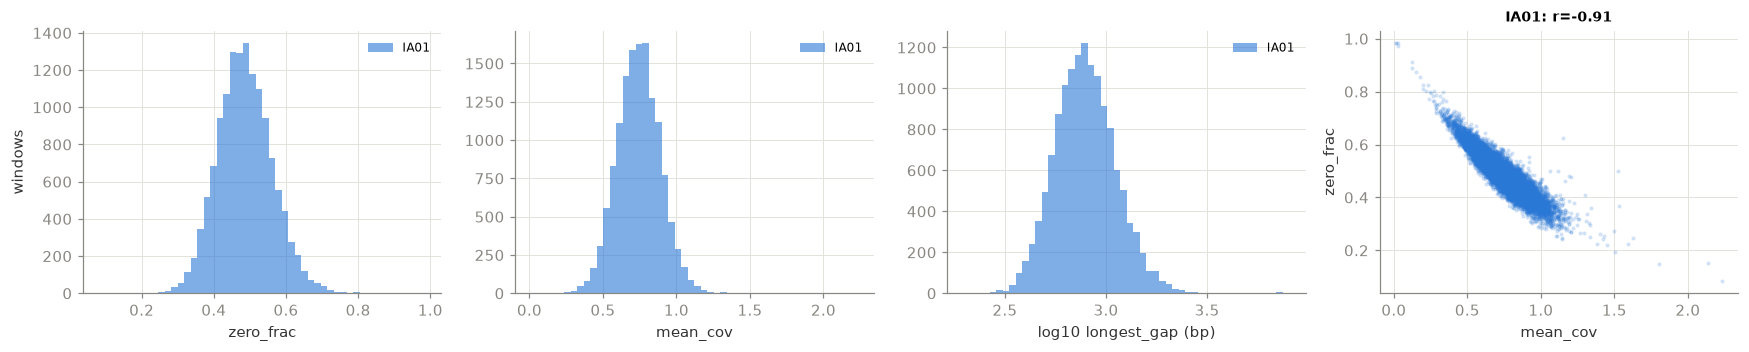

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.3))
for s, q in qc.items():
    axes[0].hist(q["zero_frac"], bins=50, alpha=0.6, color=SCOL[s], label=s)
    axes[1].hist(q["mean_cov"], bins=50, alpha=0.6, color=SCOL[s], label=s)
    axes[2].hist(np.log10(q["longest_gap"].clip(lower=1)), bins=50, alpha=0.6, color=SCOL[s], label=s)
    axes[3].scatter(q["mean_cov"], q["zero_frac"], s=3, alpha=0.15, color=SCOL[s], rasterized=True)
for ax, xl in zip(axes, ["zero_frac", "mean_cov", "log10 longest_gap (bp)", "mean_cov"]):
    ax.set_xlabel(xl)
axes[0].set_ylabel("windows"); axes[3].set_ylabel("zero_frac")
for ax in axes[:3]:
    ax.legend(fontsize=8)
r = ", ".join(f"{s}: r={q['mean_cov'].corr(q['zero_frac']):+.2f}" for s, q in qc.items())
axes[3].set_title(r, fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "qc_distributions.png", bbox_inches="tight"); plt.show()

## 3. Periodogram vs coverage

Windows split into quartiles of `zero_frac` (best = most covered). Left: mean periodogram, raw. Middle: each
gene scaled to its own mean over 120–280 bp, i.e. spectrum *shape*. Right: `band_ratio` per quartile.

If the normalised curves overlay, poor coverage lowers the whole spectrum without removing the nucleosome peak.

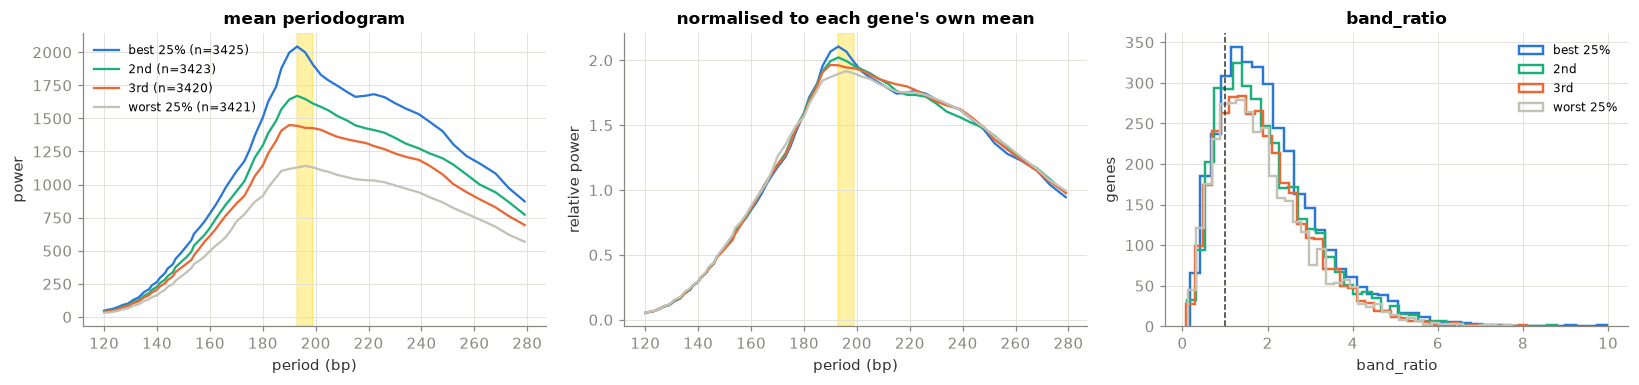

,zero_frac median,mean_cov median,band_power median,band_ratio median
zero_frac,,,,
best 25%,0.401,0.901,1628.305,1.823
2nd,0.460,0.785,1349.790,1.747
3rd,0.507,0.697,1181.609,1.745
worst 25%,0.573,0.578,904.653,1.676


IA01: corr(zero_frac, band_power) = -0.264 | corr(zero_frac, band_ratio) = -0.049


In [4]:
QN = ["best 25%", "2nd", "3rd", "worst 25%"]
QC_COL = dict(zip(QN, ["#2a78d6", "#1baf7a", "#eb6834", "#c3c2b7"]))
s0 = SAMPLES[0]
q0, f0 = qc[s0], fft[s0]
per = f0.columns.to_numpy()
band = (per >= BAND[0]) & (per <= BAND[1])
qt = pd.qcut(q0["zero_frac"], 4, labels=QN)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for k in QN:
    sub = f0[(qt == k).to_numpy()]
    axes[0].plot(per, sub.mean(), color=QC_COL[k], label=f"{k} (n={len(sub)})")
    axes[1].plot(per, sub.div(sub.mean(axis=1), axis=0).mean(), color=QC_COL[k])
for ax in axes[:2]:
    ax.axvspan(*BAND, color="gold", alpha=0.35, zorder=0); ax.set_xlabel("period (bp)")
axes[0].set_ylabel("power"); axes[0].set_title("mean periodogram"); axes[0].legend(fontsize=8)
axes[1].set_ylabel("relative power"); axes[1].set_title("normalised to each gene's own mean")
for k in QN:
    axes[2].hist(q0.loc[(qt == k).to_numpy(), "band_ratio"], bins=40, histtype="step", lw=1.6,
                 color=QC_COL[k], label=k)
axes[2].axvline(1, color=INK, ls="--", lw=1)
axes[2].set_xlabel("band_ratio"); axes[2].set_ylabel("genes"); axes[2].set_title("band_ratio"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / f"qc_periodogram_{s0}.png", bbox_inches="tight"); plt.show()

tab = pd.DataFrame({
    "zero_frac median": q0.groupby(qt, observed=True)["zero_frac"].median(),
    "mean_cov median": q0.groupby(qt, observed=True)["mean_cov"].median(),
    "band_power median": q0.groupby(qt, observed=True)["band_power"].median(),
    "band_ratio median": q0.groupby(qt, observed=True)["band_ratio"].median()}).loc[QN]
display(tab.round(3))
print(f"{s0}: corr(zero_frac, band_power) = {q0['zero_frac'].corr(q0['band_power']):+.3f} | "
      f"corr(zero_frac, band_ratio) = {q0['zero_frac'].corr(q0['band_ratio']):+.3f}")

## 4. Does dropping low-coverage windows change the ranking?

Drop the worst-covered share of windows by `zero_frac`, redo `correlate.py` (Pearson of `band_power` against
each group's mean expression), and report:

- `strongest r` — most negative correlation
- `immune - other` — gap between median immune and median other correlation, the separation to judge on
- `immune in top 20` — immune groups among the 20 most negative

`strongest r` moves with gene count alone, so judge on `immune - other`.

In [5]:
def rank_stats(score, genes):
    g = ref.index.intersection(genes)
    r = ref.loc[g].corrwith(score[g]).sort_values()
    med = {k: r[lab[r.index] == k].median() for k in LABELS}
    return {"genes": len(g), "strongest r": r.min(), "top group": r.index[0],
            "immune median": med["immune"], "other median": med["other"],
            "control median": med["negative control"],
            "immune - other": med["immune"] - med["other"],
            "immune in top 20": int((lab[r.index[:20]] == "immune").sum())}

for s in SAMPLES:
    q = qc[s]
    rows = []
    for d in DROP_QUANTILES:
        thr = q["zero_frac"].quantile(1 - d) if d else np.inf
        keep = q.index[q["zero_frac"] < thr]
        rows.append({"drop worst": f"{d:.0%}", **rank_stats(q["band_power"], keep)})
    t = pd.DataFrame(rows).set_index("drop worst")
    t.to_csv(OUT_DIR / f"qc_threshold_scan_{s}.csv")
    print(s); display(t.round(4))

IA01


,genes,strongest r,top group,immune median,other median,control median,immune - other,immune in top 20
drop worst,,,,,,,,
0%,13463,-0.0925,monocyte_Blood,-0.0532,-0.0308,-0.0139,-0.0225,20
1%,13335,-0.0913,monocyte_Blood,-0.0535,-0.0305,-0.0142,-0.0230,20
5%,12799,-0.0848,classical monocyte_Blood,-0.0505,-0.0288,-0.0123,-0.0216,20
10%,12128,-0.0846,classical monocyte_Blood,-0.0495,-0.0266,-0.0103,-0.0229,20
25%,10104,-0.0827,classical monocyte_Blood,-0.0481,-0.0235,-0.0102,-0.0245,20
50%,6720,-0.0815,intermediate monocyte_Lymph_Node,-0.0504,-0.0244,-0.0101,-0.0260,20


## 5. Coverage-adjusted correlation

`band_power` correlates with coverage, so part of the ranking could be depth rather than nucleosome structure.
Partial correlation: regress both `band_power` and every group's expression on `mean_cov` + `zero_frac`, then
correlate the residuals.

Same columns as above. If `immune - other` survives, the signal is not coverage.

In [6]:
rows = []
for s in SAMPLES:
    q = qc[s]
    g = ref.index.intersection(q.index)
    X = np.column_stack([np.ones(len(g)), q.loc[g, "mean_cov"], q.loc[g, "zero_frac"]])
    resid = lambda M: M - X @ np.linalg.lstsq(X, M, rcond=None)[0]
    score_adj = pd.Series(resid(q.loc[g, "band_power"].to_numpy()[:, None]).ravel(), index=g)
    expr_adj = pd.DataFrame(resid(ref.loc[g].to_numpy()), index=g, columns=ref.columns)
    raw = rank_stats(q["band_power"], g)
    r = expr_adj.corrwith(score_adj).sort_values()
    med = {k: r[lab[r.index] == k].median() for k in LABELS}
    adj = {"genes": len(g), "strongest r": r.min(), "top group": r.index[0],
           "immune median": med["immune"], "other median": med["other"],
           "control median": med["negative control"],
           "immune - other": med["immune"] - med["other"],
           "immune in top 20": int((lab[r.index[:20]] == "immune").sum())}
    rows += [{"sample": s, "score": "raw", **raw}, {"sample": s, "score": "coverage-adjusted", **adj}]
adj_tab = pd.DataFrame(rows).set_index(["sample", "score"])
adj_tab.to_csv(OUT_DIR / "qc_coverage_adjusted.csv")
display(adj_tab.round(4))

genes  strongest r          top group  \
sample score                                                      
IA01   raw                13463      -0.0925     monocyte_Blood   
       coverage-adjusted  13463      -0.0575  macrophage_Kidney   

                          immune median  other median  control median  \
sample score                                                            
IA01   raw                      -0.0532       -0.0308         -0.0139   
       coverage-adjusted        -0.0380       -0.0212         -0.0081   

                          immune - other  immune in top 20  
sample score                                                
IA01   raw                       -0.0225                20  
       coverage-adjusted         -0.0168                20

## 6. Example windows

Rows: windows at the best, median and worst `zero_frac`. Columns: coverage over the full window; raw WPS over
the first 2 kb; WPS after the `fft_path.R` filter (recursive IIR, coefficients `1/seq(5,100,4)`, minus the 10%
trimmed mean); periodogram with the 193–199 bp band shaded.

Note on the bottom rows: a window with almost no coverage has a flat WPS, yet still produces a smooth
periodogram peaking near the band — `band_ratio` ≈ 1.86 against a 1.75 median, i.e. **`band_ratio` does not
flag empty windows**, since that shape comes from the filter and taper rather than from data. `band_power`
does: ≈30 against a median of 1234.

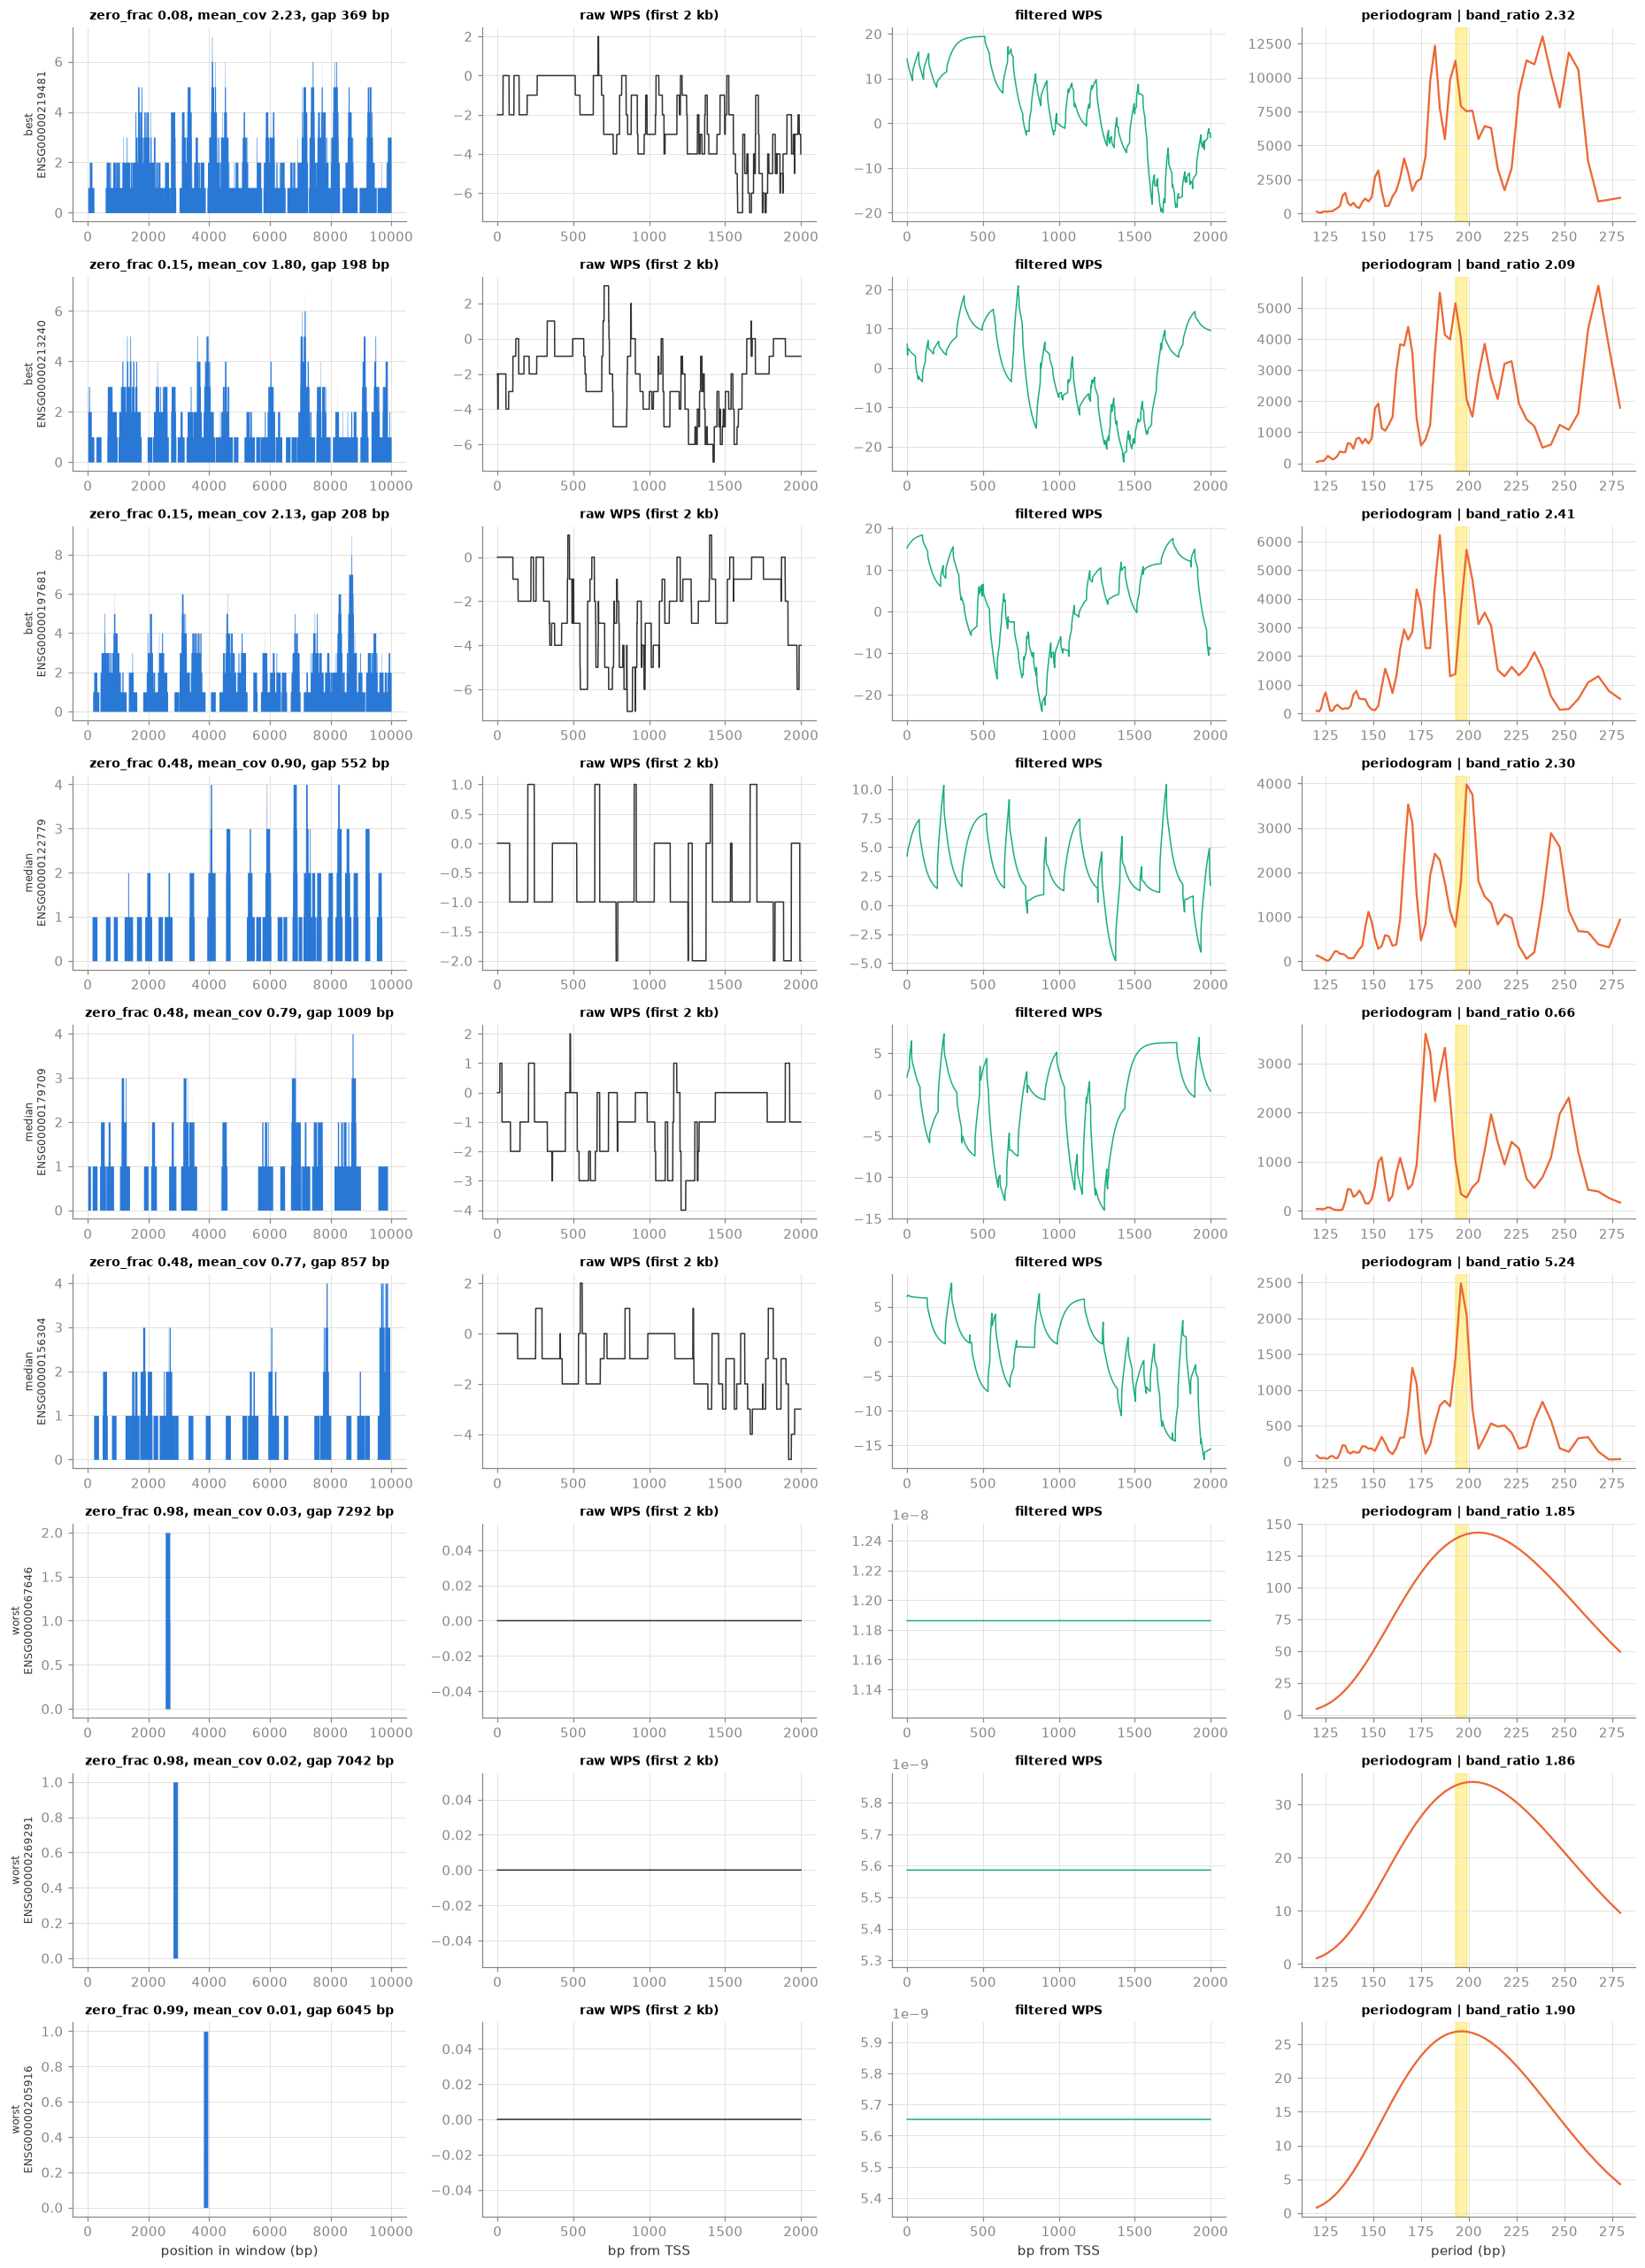

In [7]:
try:
    from scipy.signal import lfilter
    from scipy.stats import trim_mean
except ImportError:                                  # no scipy: same result, slower
    def lfilter(b, a, x):
        y = np.empty(len(x)); f = -np.asarray(a[1:])
        for t in range(len(x)):
            y[t] = x[t] + sum(f[k] * y[t - 1 - k] for k in range(min(len(f), t)))
        return y
    def trim_mean(x, p):
        xs = np.sort(x); k = int(len(xs) * p)
        return xs[k:len(xs) - k].mean()

FCOEF = 1.0 / np.arange(5, 101, 4)

def nextn(n, fac=(2, 3, 5)):
    while True:
        m = n
        for f in fac:
            while m % f == 0:
                m //= f
        if m == 1:
            return n
        n += 1

def pipeline_filter(x):
    y = np.asarray(lfilter([1.0], np.concatenate([[1.0], -FCOEF]), np.concatenate([x[:300], x])))[300:]
    return y - trim_mean(y, 0.1)

def spec_pgram(x, taper=0.3, pad=0.3):
    x = np.asarray(x, float); N0 = len(x)
    t = np.arange(1, N0 + 1) - (N0 + 1) / 2
    x = x - x.mean() - np.sum(x * t) * t / (N0 * (N0 ** 2 - 1) / 12)
    m = int(N0 * taper)
    w = 0.5 * (1 - np.cos(np.pi * np.arange(1, 2 * m, 2) / (2 * m)))
    x = x * np.concatenate([w, np.ones(N0 - 2 * m), w[::-1]])
    N = nextn(N0 + int(N0 * pad))
    x = np.concatenate([x, np.zeros(N - N0)])
    pg = np.abs(np.fft.fft(x)) ** 2 / N0
    pg[0] = 0.5 * (pg[1] + pg[-1])
    pg = np.convolve(np.concatenate([pg[-1:], pg, pg[:1]]), [0.25, 0.5, 0.25], mode="valid")
    ns = N // 2
    return N / np.arange(1, ns + 1), (pg / (1 - 1.25 * taper))[1:ns + 1]

ranked = q0.sort_values("zero_frac")
mid = len(ranked) // 2
picks = {"best": ranked.index[:N_EXAMPLES], "median": ranked.index[mid:mid + N_EXAMPLES],
         "worst": ranked.index[-N_EXAMPLES:]}
ZOOM = 2000
body = WORKFLOW / "results" / s0 / "body"

fig, axes = plt.subplots(len(picks) * N_EXAMPLES, 4, figsize=(17, 2.6 * len(picks) * N_EXAMPLES))
row = 0
for kind, genes in picks.items():
    for gene in genes:
        a = pd.read_csv(body / f"block_{gene}.tsv.gz", sep="\t", header=None, usecols=[2, 4],
                        dtype=np.float64).to_numpy()
        cov, wps = a[:, 0], a[:, 1]
        filt = pipeline_filter(wps)
        p, sp = spec_pgram(filt)
        sel = (p >= PERIOD_RANGE[0]) & (p <= PERIOD_RANGE[1])
        m = q0.loc[gene]
        axes[row, 0].fill_between(np.arange(len(cov)), cov, color="#2a78d6", lw=0)
        axes[row, 0].set_ylabel(f"{kind}\n{gene}", fontsize=8)
        axes[row, 0].set_title(f"zero_frac {m['zero_frac']:.2f}, mean_cov {m['mean_cov']:.2f}, "
                               f"gap {m['longest_gap']:.0f} bp", fontsize=9)
        axes[row, 1].plot(np.arange(ZOOM), wps[:ZOOM], color=INK, lw=1)
        axes[row, 1].set_title("raw WPS (first 2 kb)", fontsize=9)
        axes[row, 2].plot(np.arange(ZOOM), filt[:ZOOM], color="#1baf7a", lw=1)
        axes[row, 2].set_title("filtered WPS", fontsize=9)
        axes[row, 3].plot(p[sel], sp[sel], color="#eb6834")
        axes[row, 3].axvspan(*BAND, color="gold", alpha=0.35, zorder=0)
        axes[row, 3].set_title(f"periodogram | band_ratio {m['band_ratio']:.2f}", fontsize=9)
        row += 1
for ax, xl in zip(axes[-1], ["position in window (bp)", "bp from TSS", "bp from TSS", "period (bp)"]):
    ax.set_xlabel(xl)
plt.tight_layout(); plt.savefig(OUT_DIR / f"qc_examples_{s0}.png", bbox_inches="tight"); plt.show()

## Outputs

`qc_output/`: `window_qc_<sample>.csv` (per-window metrics), `qc_threshold_scan_<sample>.csv`,
`qc_coverage_adjusted.csv`, `qc_distributions.png`, `qc_periodogram_<sample>.png`, `qc_examples_<sample>.png`.